# Solver de cubo mágico 3×3



## Preparação

As coordenadas, os mapas de movimento e as funções de visualização ficam em `cubo.py`. Aqui montamos estados e fazemos experimentos com essas funções.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import importlib
import cubo

importlib.reload(cubo)

from cubo import (
    ORDEM_FACES,
    coordenadas_U,
    coordenadas_L,
    coordenadas_F,
    coordenadas_R,
    coordenadas_B,
    coordenadas_D,
    print_cubo,
    plotar_cubo,
    girar_cubo,
    gerar_mapa_movimento,
    mapas_movimentos,
    scramble,
    scramble_aleatorio,
)


## Estado do cubo

O estado é um vetor de 54 adesivos, com nove adesivos por face na ordem `[U, L, F, R, B, D]`. As cores abaixo identificam as seis faces do cubo resolvido.

In [6]:
cores_por_face = ['W', 'G', 'R', 'B', 'O', 'Y']
cubo_resolvido = np.repeat(cores_por_face, 9)
ids = np.arange(54)

print_cubo(cubo_resolvido)
print('--------------------------------------')
print_cubo(ids)


       W W W
       W W W
       W W W

G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y
--------------------------------------
       0 1 2
       3 4 5
       6 7 8

9 10 11  18 19 20  27 28 29  36 37 38
12 13 14  21 22 23  30 31 32  39 40 41
15 16 17  24 25 26  33 34 35  42 43 44

       45 46 47
       48 49 50
       51 52 53


## Coordenadas em R³ e visualização

Cada adesivo tem uma posição no espaço. Adesivos que pertencem à mesma peça (canto, aresta ou centro) compartilham a mesma coordenada. As grades das seis faces são definidas em `cubo.py`; aqui inspecionamos essa convenção e plotamos o estado resolvido uma vez.

Face U: centro em [0 0 1]
Face L: centro em [0 1 0]
Face F: centro em [1 0 0]
Face R: centro em [ 0 -1  0]
Face B: centro em [-1  0  0]
Face D: centro em [ 0  0 -1]


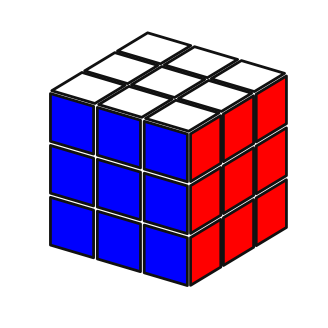

In [7]:
for face, grade in zip(
    ORDEM_FACES,
    (coordenadas_U, coordenadas_L, coordenadas_F,
     coordenadas_R, coordenadas_B, coordenadas_D),
):
    print(f"Face {face}: centro em {grade[1, 1]}")

plotar_cubo(cubo_resolvido)
plt.show()


## Testes dos movimentos

A seguir, comparamos o movimento `U` geométrico com o mapa vetorial escrito manualmente, visualizamos uma volta completa de `F` e conferimos propriedades dos mapas gerados.

### Comparar o movimento U geométrico com o mapa manual

O mapa manual serve como uma referência independente para conferir se a geração geométrica produz o mesmo movimento.

In [8]:
movimento_U = np.arange(54)

# Adesivos das arestas que passam ao redor da face U.
movimento_U[9:12] = [18, 19, 20]
movimento_U[18:21] = [27, 28, 29]
movimento_U[27:30] = [36, 37, 38]
movimento_U[36:39] = [9, 10, 11]

# Giro horário da própria face U, vista de fora.
movimento_U[0:9] = [6, 3, 0, 7, 4, 1, 8, 5, 2]

mapa_U_geometrico = gerar_mapa_movimento("U")

if np.array_equal(mapa_U_geometrico, movimento_U):
    print("U geométrico: igual ao mapa U manual.")
else:
    print("U geométrico: diferente do mapa U manual.")


U geométrico: igual ao mapa U manual.


### Visualizar uma volta completa de F

Os cinco painéis mostram o cubo inicial e os estados após um, dois, três e quatro giros de `F`. O último deve voltar ao estado inicial.

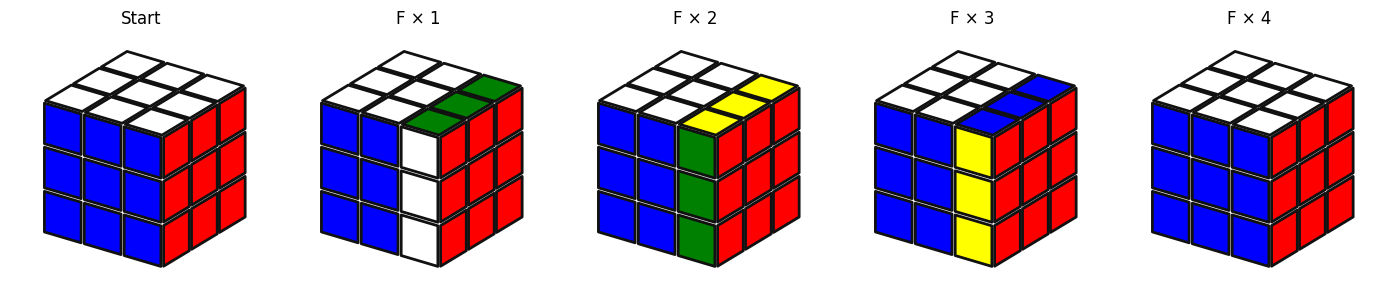

In [9]:
fig, axs = plt.subplots(
    1, 5,
    figsize=(14, 3),
    subplot_kw={"projection": "3d"},
)

estado = cubo_resolvido.copy()
plotar_cubo(estado, ax=axs[0])
axs[0].set_title("Start")

for numero_giros in range(1, 5):
    estado = girar_cubo(estado, mapas_movimentos["F"])
    plotar_cubo(estado, ax=axs[numero_giros])
    axs[numero_giros].set_title(f"F × {numero_giros}")

plt.tight_layout()
plt.show()


### Inverso, giro duplo e quatro giros

Para cada face, o giro seguido do inverso deve restaurar o estado; dois giros devem equivaler ao mapa de giro duplo; quatro giros devem restaurar o estado.

In [10]:
ids = np.arange(54)

for face in ORDEM_FACES:
    mapa = mapas_movimentos[face]
    inverso = mapas_movimentos[face + "'"]
    giro_duplo = mapas_movimentos[face + "2"]

    volta_com_inverso = girar_cubo(girar_cubo(ids, mapa), inverso)
    dois_giros = girar_cubo(girar_cubo(ids, mapa), mapa)
    quatro_giros = girar_cubo(girar_cubo(dois_giros, mapa), mapa)

    assert np.array_equal(volta_com_inverso, ids)
    assert np.array_equal(dois_giros, girar_cubo(ids, giro_duplo))
    assert np.array_equal(quatro_giros, ids)

    print(f"{face}: inverso, giro duplo e quatro giros conferidos.")


U: inverso, giro duplo e quatro giros conferidos.
L: inverso, giro duplo e quatro giros conferidos.
F: inverso, giro duplo e quatro giros conferidos.
R: inverso, giro duplo e quatro giros conferidos.
B: inverso, giro duplo e quatro giros conferidos.
D: inverso, giro duplo e quatro giros conferidos.


### Centros e peças continuam juntos

Usamos adesivos numerados para acompanhar cada adesivo individualmente. Os seis centros devem continuar nos mesmos índices. Os adesivos que começam na mesma coordenada formam uma peça e devem continuar na mesma coordenada após os movimentos.

In [11]:
posicoes = np.concatenate([
    coordenadas_U.reshape(9, 3),
    coordenadas_L.reshape(9, 3),
    coordenadas_F.reshape(9, 3),
    coordenadas_R.reshape(9, 3),
    coordenadas_B.reshape(9, 3),
    coordenadas_D.reshape(9, 3),
])

# Agrupa adesivos pela coordenada inicial de cada peça.
grupos_de_pecas = {}
for id_adesivo, posicao in enumerate(posicoes):
    grupos_de_pecas.setdefault(tuple(posicao), []).append(id_adesivo)

# Aplica uma sequência de movimentos aos identificadores dos adesivos.
estado_ids = np.arange(54)
sequencia = ["F", "R", "U'", "B2", "L", "D'"]
for movimento in sequencia:
    estado_ids = girar_cubo(estado_ids, mapas_movimentos[movimento])

# Os centros (índices do meio de cada face) ficam fixos nos giros de face.
indices_centros = [4, 13, 22, 31, 40, 49]
assert all(estado_ids[indice] == indice for indice in indices_centros)
print("Centros: continuam nas mesmas posições.")

# Cada adesivo de uma peça deve terminar na mesma coordenada que os outros.
for ids_peca in grupos_de_pecas.values():
    destinos = [np.flatnonzero(estado_ids == id_adesivo)[0] for id_adesivo in ids_peca]
    posicoes_atuais = {tuple(posicoes[indice]) for indice in destinos}
    assert len(posicoes_atuais) == 1

print("Peças: todos os adesivos de cada canto, aresta e centro continuam juntos.")


Centros: continuam nas mesmas posições.
Peças: todos os adesivos de cada canto, aresta e centro continuam juntos.


## Embaralhar o cubo

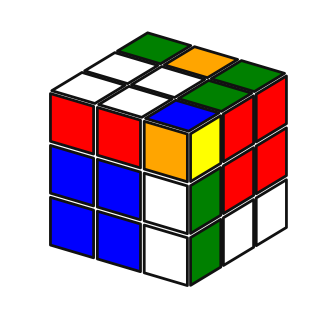

In [12]:
newcube = np.arange(54)

scrambled = scramble("UR'U2F", newcube)

plotar_cubo(scrambled, ids=True)
plt.show()


Scramble gerado:
F' L' F R D R2 D


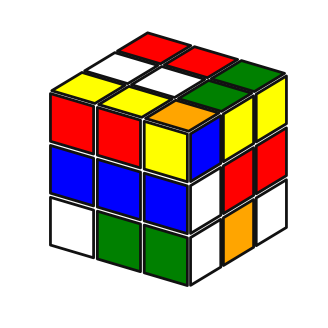

In [13]:
newcube = np.arange(54)

scrambled, sequencia = scramble_aleatorio(newcube.copy(), 7)

print("Scramble gerado:")
print(" ".join(sequencia))

plotar_cubo(scrambled, ids=True)
plt.show()
